# 21 统计入门(Fundamentals-of Statistics)

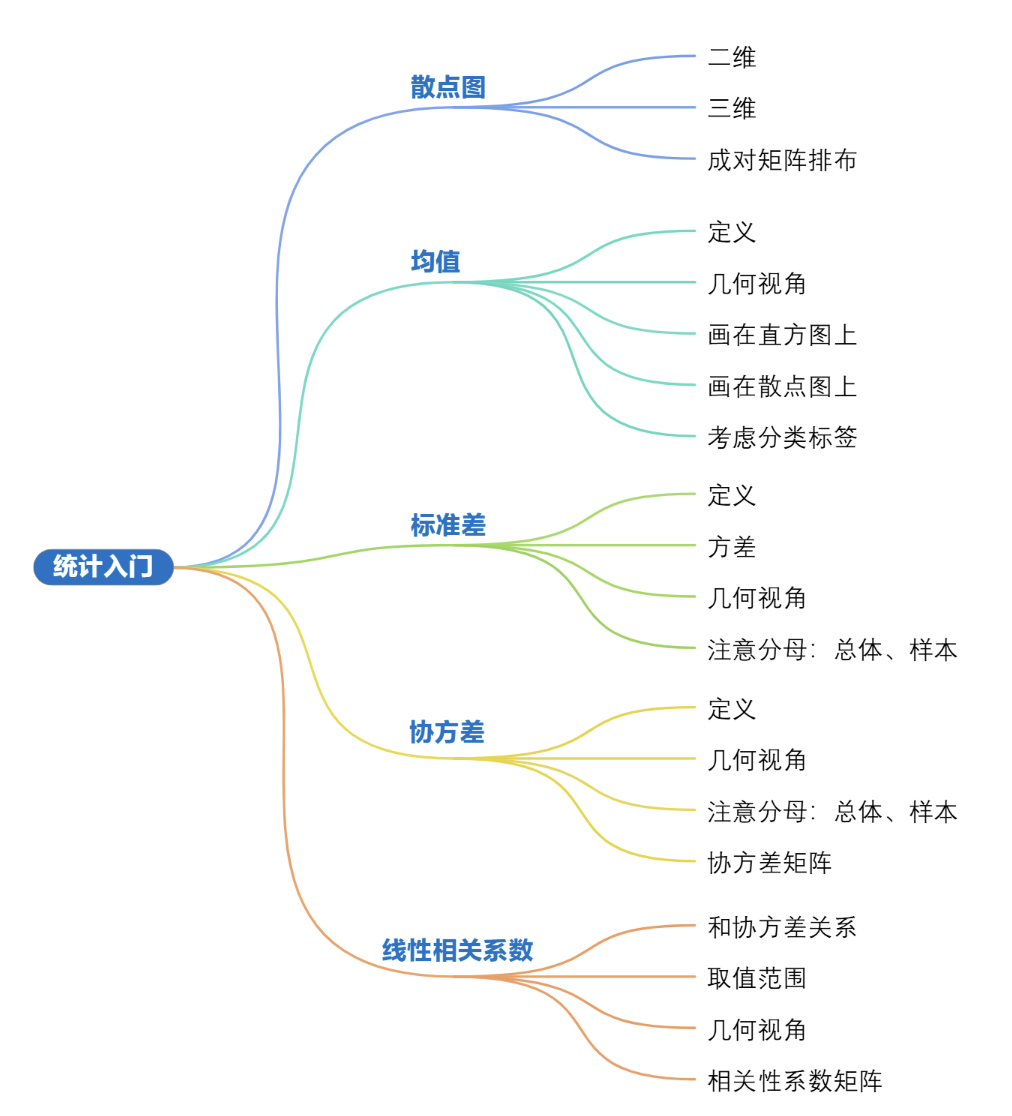

In [29]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris

In [30]:
p = plt.rcParams
p["ytick.minor.visible"] = True
p["xtick.minor.visible"] = True
p["axes.grid"] = True
p["grid.color"] = "0.5"
p["grid.linewidth"] = 0.5

In [31]:
iris_sns = sns.load_dataset("iris")

## 21.1 统计的前世今生：强国知 13 数

<font color="blue">略</font>

## 21.2 散点图：当数据遇到坐标系

<font color="blue">散点图</font>(scatterplot)。散点图将二维样本数据以点的形式展现在直角坐标系上。

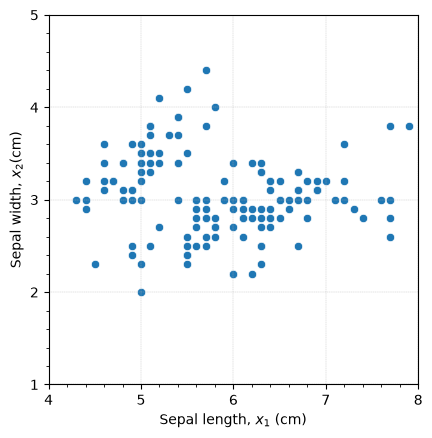

In [32]:
fig, ax = plt.subplots()

ax = sns.scatterplot(data=iris_sns, x="sepal_length", y="sepal_width")

ax.set_xlabel("Sepal length, $x_1$ (cm)")
ax.set_ylabel("Sepal width, $x_2$(cm)")
ax.set_xticks(np.arange(4, 8 + 1, step=1))
ax.set_yticks(np.arange(1, 5 + 1, step=1))
ax.axis("scaled")
ax.grid(linestyle="--", linewidth=0.25, color=[0.7, 0.7, 0.7])
ax.set_xbound(lower=4, upper=8)
ax.set_ybound(lower=1, upper=5)

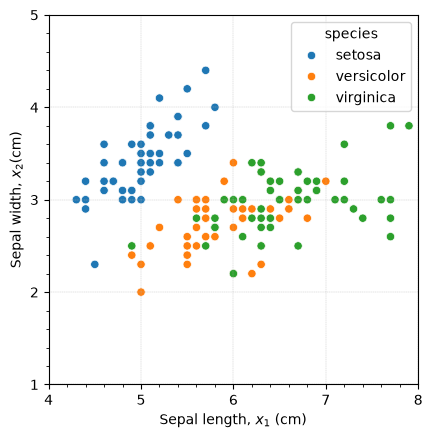

In [33]:
fig, ax = plt.subplots()

ax = sns.scatterplot(data=iris_sns, x="sepal_length", y="sepal_width", hue="species")

ax.set_xlabel("Sepal length, $x_1$ (cm)")
ax.set_ylabel("Sepal width, $x_2$(cm)")
ax.set_xticks(np.arange(4, 8 + 1, step=1))
ax.set_yticks(np.arange(1, 5 + 1, step=1))
ax.axis("scaled")
ax.grid(linestyle="--", linewidth=0.25, color=[0.7, 0.7, 0.7])
ax.set_xbound(lower=4, upper=8)
ax.set_ybound(lower=1, upper=5)

In [34]:
x1 = iris_sns["sepal_length"]
x2 = iris_sns["sepal_width"]
x3 = iris_sns["petal_length"]
labels = iris_sns["species"].copy()
labels = iris_sns["species"].map({
    "setosa": 1,
    "versicolor": 2,
    "virginica": 3
})
rainbow = plt.get_cmap("rainbow")

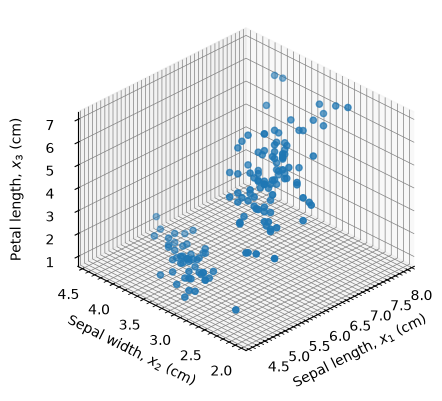

In [35]:
fig = plt.figure()
ax = plt.axes(projection="3d")
ax.scatter(x1, x2 ,x3) # 无类别信息的 3D 散点图

ax.set_xlabel("Sepal length, $x_1$ (cm)")
ax.set_ylabel("Sepal width, $x_2$ (cm)")
ax.set_zlabel("Petal length, $x_3$ (cm)")
ax.set_proj_type("ortho")
ax.view_init(azim=-135, elev=30)

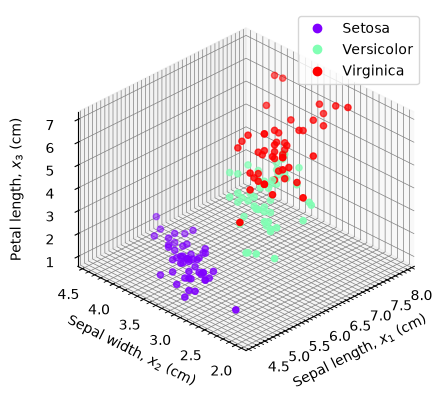

In [36]:
fig = plt.figure()
ax = plt.axes(projection="3d")
scatter_h = ax.scatter(x1, x2 ,x3, c=labels, cmap=rainbow) # 无类别信息的 3D 散点图

classes = ["Setosa", "Versicolor", "Virginica"]
plt.legend(handles=scatter_h.legend_elements()[0], labels=classes)
ax.set_xlabel("Sepal length, $x_1$ (cm)")
ax.set_ylabel("Sepal width, $x_2$ (cm)")
ax.set_zlabel("Petal length, $x_3$ (cm)")
ax.set_proj_type("ortho")
ax.view_init(azim=-135, elev=30)

### 成对特征散点图

当出现 3 个以上的特征可以使用<font color="blue">成对特征散点图</font>来展示所有的特征

16幅子图被安排成 4 × 4 矩阵的形式。其中，12 幅散点图为成对特征关系，对角线上的 4 幅图像叫做<font color="blue">概率密度估计</font>(probability density estimation)曲线。


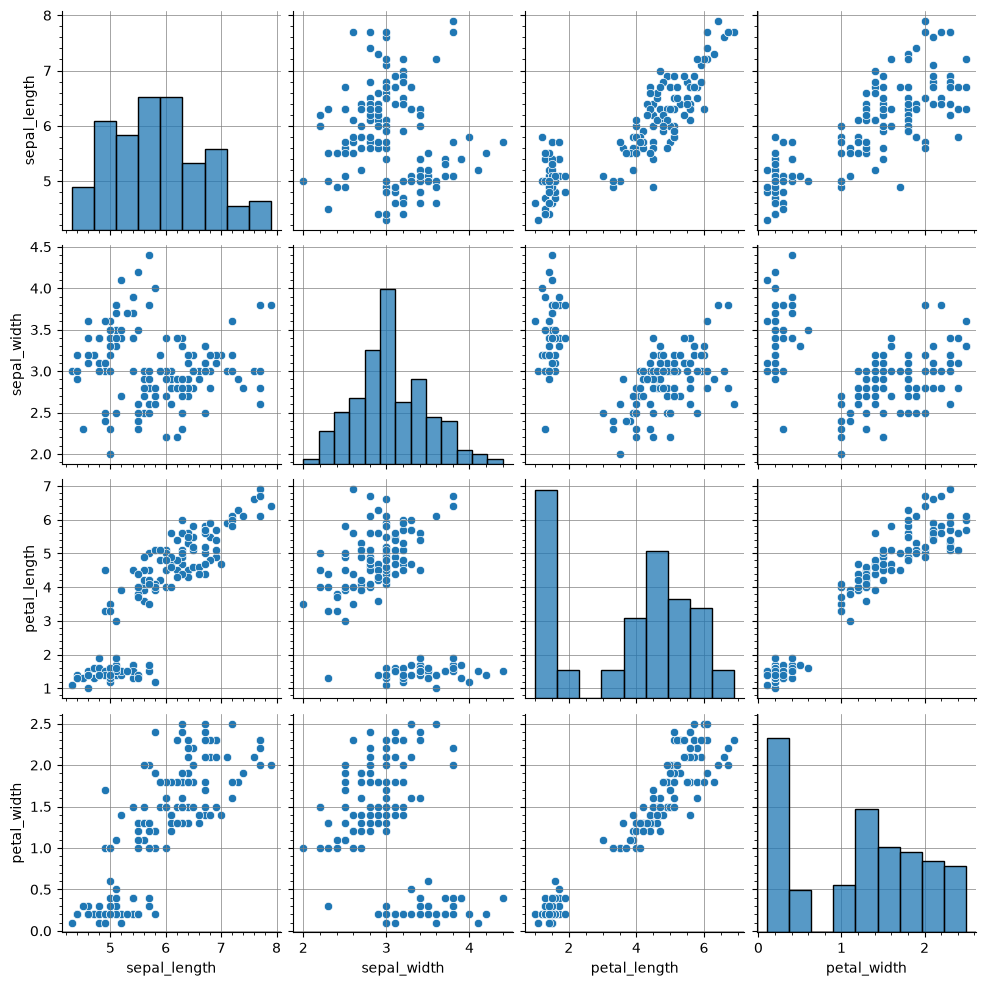

In [37]:
sns.pairplot(iris_sns)

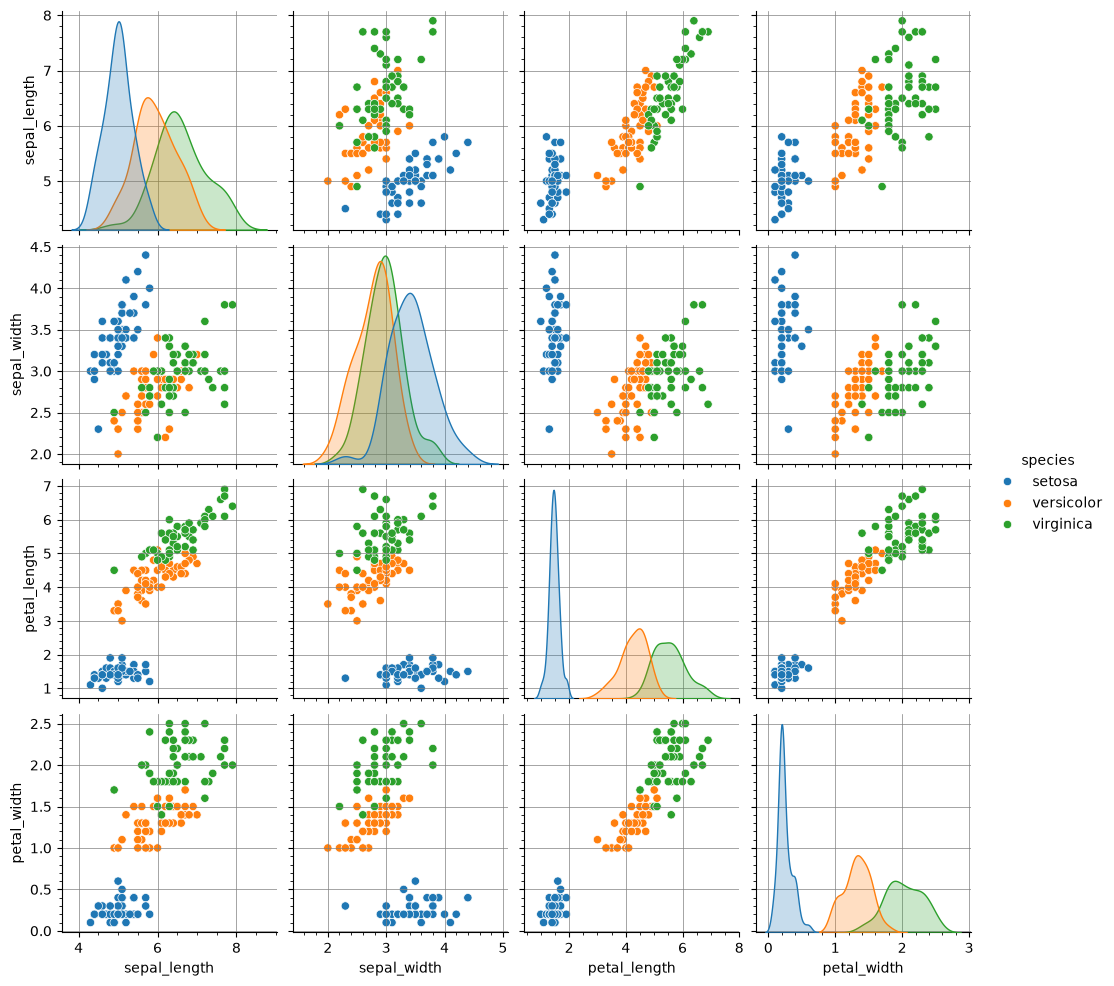

In [38]:
sns.pairplot(iris_sns, hue="species")

### 散点图的作用

利用散点图，我们可以发现数据的集中、分布程度，比如数据主要集中在哪些区域。

散点图也会揭示不同特征之间可能存在的量化关系，这就是<font color="blue>线性回归</font>(linearregression)的思路。

此外，我们还可以利用散点图发现数据是否存在离群值。<font color="blue">离群值</font>(outlier)指的是，和其他数据相比，数据中有一个或几个样本数值差异较大。

## 21.3 均值：集中程度

<font color="blue">均值</font>(average 或 mean), 也叫平均值，<font color="blue">算数平均数</font>(arithmetic average 或 arithmetic mean)。均值代表一组数据集中趋势。

均值对应的运算是，一组数据中所有数据先求和，再除以这组数据的个数。
$$
\mu_1 = \frac{1}{n}\left(\sum^{n}_{i=1}x_1^{(i)}\right)
$$

从几何角度，算数平均值相当于找到一个平衡点。
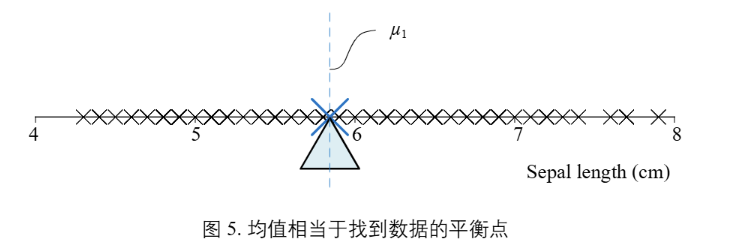

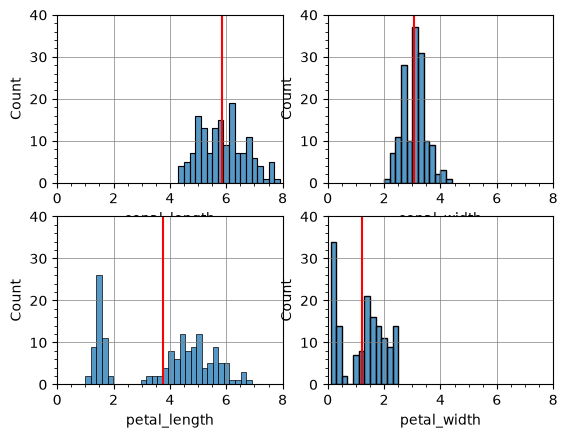

In [39]:
fig, axes = plt.subplots(2, 2)

mu_1 = iris_sns["sepal_length"].mean()
sns.histplot(data=iris_sns, x="sepal_length", binwidth=0.2, ax=axes[0][0])
axes[0][0].set_xlim([0, 8])
axes[0][0].set_ylim([0, 40])
axes[0][0].vlines(x=mu_1, ymin=0, ymax=40, color="r")

mu_2 = iris_sns["sepal_width"].mean()
sns.histplot(data=iris_sns, x="sepal_width", binwidth=0.2, ax=axes[0][1])
axes[0][1].set_xlim([0, 8])
axes[0][1].set_ylim([0, 40])
axes[0][1].vlines(x=mu_2, ymin=0, ymax=40, color="r")

mu_3 = iris_sns["petal_length"].mean()
sns.histplot(data=iris_sns, x="petal_length", binwidth=0.2, ax=axes[1][0])
axes[1][0].set_xlim([0, 8])
axes[1][0].set_ylim([0, 40])
axes[1][0].vlines(x=mu_3, ymin=0, ymax=40, color="r")

mu_4 = iris_sns["petal_width"].mean()
sns.histplot(data=iris_sns, x="petal_width", binwidth=0.2, ax=axes[1][1])
axes[1][1].set_xlim([0, 8])
axes[1][1].set_ylim([0, 40])
axes[1][1].vlines(x=mu_4, ymin=0, ymax=40, color="r")

### 考虑分类

我们在计算均值的时候，也可以考虑分类。我们可以三类不同标签条样木数据均值位置可视化。
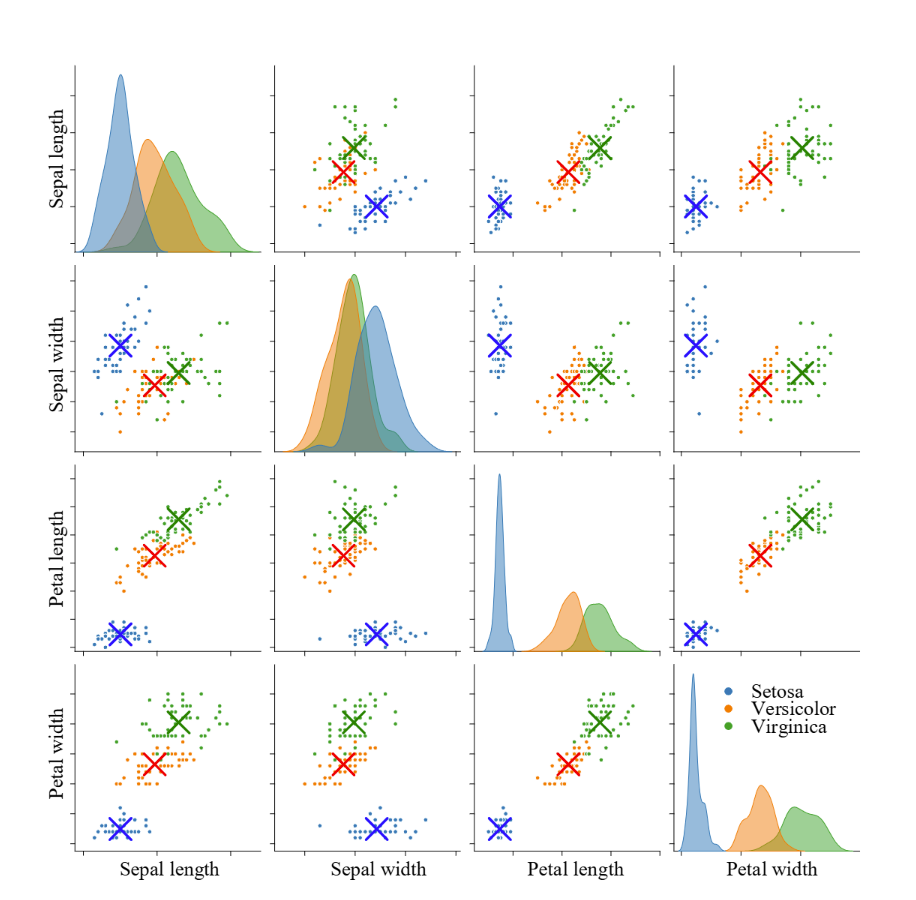


## 21.4 标准差：离散程度

<font color="blue">标准差</font>(standard deviation)描述一组数值以均值 $\mu$ 为基准的分散程度。
$$
\sigma_1=\sqrt{\frac{1}{n-1}\sum^{n}_{i=1}\left(x_1^{(i)}-\mu_{1}\right)^2}
$$

标准差的平方为<font color="blue">方差</font>(variance):
$$
\mathrm{var}(X_1)=\sigma_1^2=\frac{1}{n-1}\sum^{n}_{i=1}\left(x_1^{(i)}-\mu_{1}\right)^2
$$

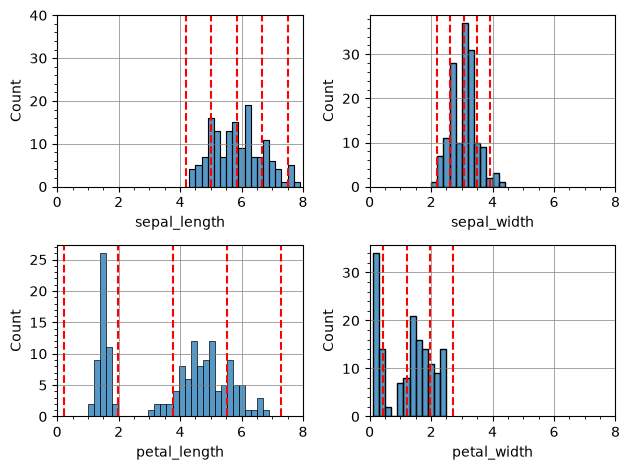

In [44]:
# 为直方图添加均值和标准差线
num = 0
fig, axes = plt.subplots(2, 2)
for i in [0, 1]:
    for j in [0, 1]:
        sns.histplot(data=iris_sns, x=iris_sns.columns[num], 
                    binwidth=0.2, ax=axes[i][j])
        axes[i][j].set_xlim([0, 8])
        axes[0][0].set_ylim([0, 40])

        mu = iris_sns.iloc[:, num].mean()
        std = iris_sns.iloc[:, num].std()

        axes[i][j].axvline(x=mu, color="r", linestyle="--")
        axes[i][j].axvline(x=mu - std, color='r', linestyle='--')  # 均值-1标准差
        axes[i][j].axvline(x=mu + std, color='r', linestyle='--')  # 均值+1标准差
        axes[i][j].axvline(x=mu - 2*std, color='r', linestyle='--')  # 均值-2标准差
        axes[i][j].axvline(x=mu + 2*std, color='r', linestyle='--')  # 均值+2标准差
        num = num + 1

plt.tight_layout()

## 21.5 协方差：联合变化程度

<font color="blue">协方差</font>(covariance)描述的是随机变量联合变化程度。
$$
\mathrm{cov}(X_1, X_2) = \frac{1}{n-1}\sum^{n}_{i=1}\left(x_1^{(i)}-\mu_1\right)\left(x_2^{(i)}-\mu_2\right)
$$

从几何视角，$\left(x_1^{(i)}-\mu_1\right)\left(x_2^{(i)}-\mu_2\right)$ 相当于以 $\left(x_1^{(i)}-\mu_1\right)$ 和 $\left(x_2^{(i)}-\mu_2\right)$ 为边的矩形面积。

当 $\left(x_1^{(i)}-\mu_1\right)$ 和 $\left(x_2^{(i)}-\mu_2\right)$ 同号，面积为正。
当 $\left(x_1^{(i)}-\mu_1\right)$ 和 $\left(x_2^{(i)}-\mu_2\right)$ 异号，面积为负。

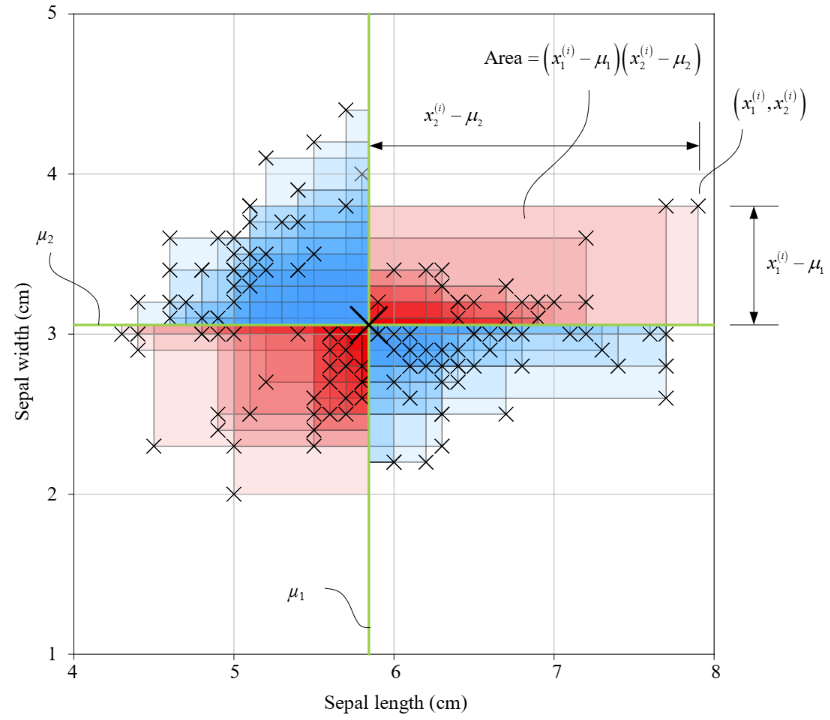

<font color="green">红色矩阵越多，表现一个正相关的协同关系；蓝色矩阵越多，表现一个负相关的协同关系</font>

### 协方差矩阵

由方差和协方差构成的矩阵叫做<font color="blue">协方差矩阵</font>(covariancematrix)，也叫方差-协方差矩阵(variance-covariance matrix).

协方差矩阵为方阵。矩阵中对角线上元素为方差。

In [45]:
# 协方差矩阵
iris_sns.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Text(0.5, 1.0, '$\\Sigma$')

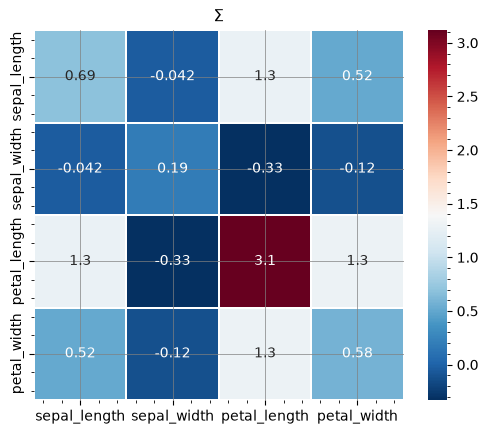

In [46]:
SIDMA = iris_sns.iloc[:, :-1].cov()  # 计算协方差矩阵
fig, axs = plt.subplots()
h = sns.heatmap(SIDMA, cmap="RdBu_r", linewidths=.05, annot=True)
h.set_aspect("equal")
h.set_title(r"$\Sigma$")

### 考虑标签

当然，在计算协方差时，我们也可以考虑到数据标签。

Text(0.5, 1.0, 'Y = 2, virginica')

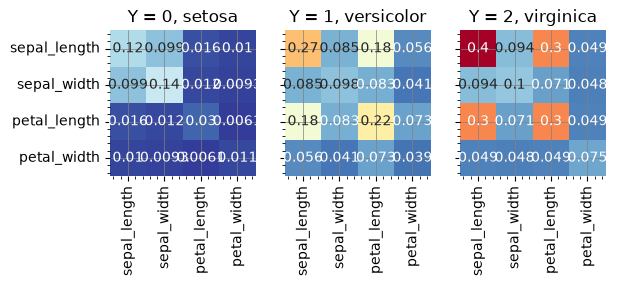

In [50]:
f, (ax1, ax2, ax3) = plt.subplots(1, 3, sharey=True)

g1 = sns.heatmap(iris_sns.loc[iris_sns["species"] == "setosa"].iloc[:, :-1].cov(),
                 cmap="RdYlBu_r", annot=True, cbar=False, ax=ax1, square=True,
                 vmax=0.4, vmin=0)
ax1.set_title("Y = 0, setosa")

g2 = sns.heatmap(iris_sns.loc[iris_sns["species"] == "versicolor"].iloc[:, :-1].cov(),
                 cmap="RdYlBu_r", annot=True, cbar=False, ax=ax2, square=True,
                 vmax=0.4, vmin=0)
ax2.set_title("Y = 1, versicolor")

g3 = sns.heatmap(iris_sns.loc[iris_sns["species"] == "virginica"].iloc[:, :-1].cov(),
                 cmap="RdYlBu_r", annot=True, cbar=False, ax=ax3, square=True,
                 vmax=0.4, vmin=0)
ax3.set_title("Y = 2, virginica")

## 21.6 线性相关性系数：线性关系强弱

<font color="blue">线性相关系数</font>(linear correlation coefficient 或 correlation coefficient)。线性相关系数也叫<font color="blue">皮尔逊相关系数</font>(Pearson correlation coefficient)，它刻画随机变量线性关系的强度，具体定义为:
$$
\rho_{1,2}=\mathrm{corr}(X_1,X_2)=\frac{\mathrm{cov}(X_1,X_2)}{\sigma_1\sigma_2}
$$

$\rho$ 的取值范围在 $[-1,1]$。可以发现 $\rho$ 相当于协方差归一化。也相当于对两个随机变量的 $z$ 分数求协方差:
$$
\rho_{1,2}=\mathrm{corr}(X_1,X_2)=\mathrm{cov}\left(\frac{X_1-\mu_1}{\sigma_1},\frac{X_2-\mu_2}{\sigma_2}\right)
$$

### 相关性系数矩阵

相关性系数构成的矩阵叫做<font color="blue">相关性系数矩阵</font>(correlation matrix) $P$:
$$
\boldsymbol{P}=
\begin{bmatrix}
1 & \rho_{1,2} & \rho_{1,3} & \rho_{1,4} \\
\rho_{2,1} & 1 & \rho_{2,3} & \rho_{2,4} \\
\rho_{3,1} & \rho_{3,2} & 1 & \rho_{3,4} \\
\rho_{4,1} & \rho_{4,2} & \rho_{4,3} & 1
\end{bmatrix}
$$

线性相关性系数的主对角元素为 1，这是因为随机变量和自身的线性相关系数为 1；非对角线元素为成对相关性系数。

Text(0.5, 1.0, '$Ρ$')

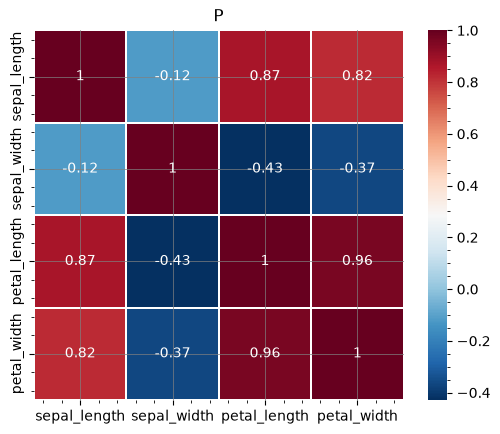

In [51]:
# 线性相关系数矩阵
RHO = iris_sns.iloc[:,:-1].corr()

fig, axs = plt.subplots()
h = sns.heatmap(RHO, cmap="RdBu_r", linewidth=.05, annot=True)
h.set_aspect("equal")
h.set_title("$\u03A1$")

### 考虑标签

Text(0.5, 1.0, 'Y = 2, virginica')

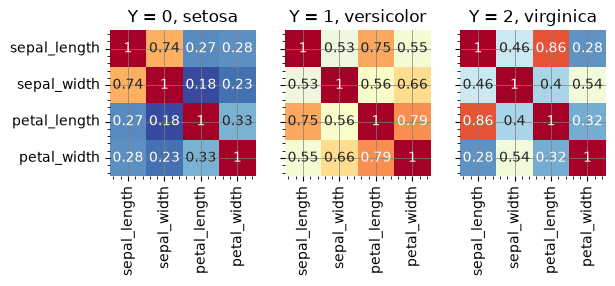

In [52]:
f, (ax1, ax2, ax3) = plt.subplots(1, 3, sharey=True)

g1 = sns.heatmap(iris_sns.loc[iris_sns["species"] == "setosa"].iloc[:, :-1].corr(),
                 cmap="RdYlBu_r", annot=True, cbar=False, ax=ax1, square=True,
                 vmax=1, vmin=0.15)
ax1.set_title("Y = 0, setosa")

g2 = sns.heatmap(iris_sns.loc[iris_sns["species"] == "versicolor"].iloc[:, :-1].corr(),
                 cmap="RdYlBu_r", annot=True, cbar=False, ax=ax2, square=True,
                 vmax=1, vmin=0.15)
ax2.set_title("Y = 1, versicolor")

g3 = sns.heatmap(iris_sns.loc[iris_sns["species"] == "virginica"].iloc[:, :-1].corr(),
                 cmap="RdYlBu_r", annot=True, cbar=False, ax=ax3, square=True,
                 vmax=1, vmin=0.15)
ax3.set_title("Y = 2, virginica")